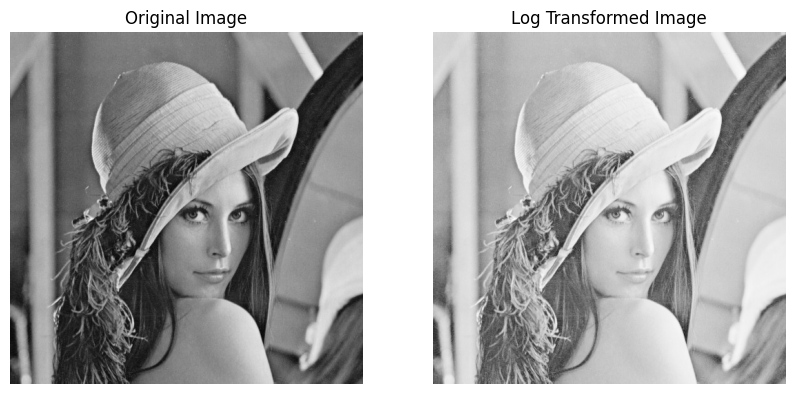

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# Download sample image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
urllib.request.urlretrieve(url, "input.jpg")

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Log transformation (c = 1)
img_float = img.astype(np.float32)
log_img = np.log1p(img_float)

# Normalize to 0-255 for display
log_img = cv2.normalize(log_img, None, 0, 255,
                        cv2.NORM_MINMAX)
log_img = log_img.astype(np.uint8)

# Display images
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(log_img, cmap="gray")
plt.title("Log Transformed Image")
plt.axis("off")
plt.show()


Enter gamma value: 0.5


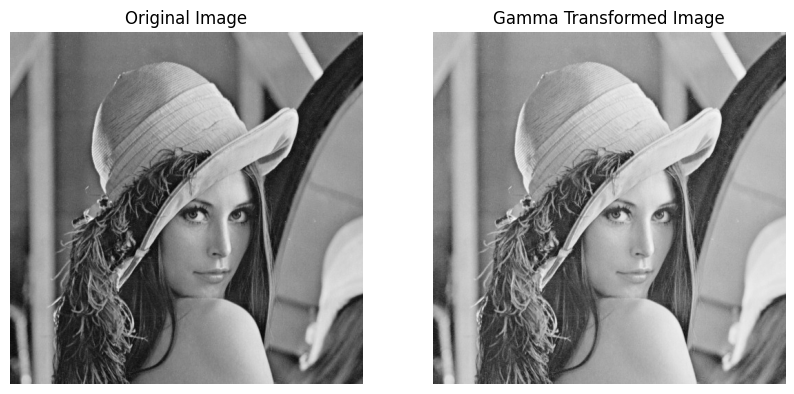

In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# Download sample image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
urllib.request.urlretrieve(url, "input.jpg")

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Input gamma
gamma = float(input("Enter gamma value: "))

if gamma <= 0:
    raise ValueError("Gamma must be positive")

# Normalize pixels to 0-1
normalized = img.astype(np.float32) / 255.0

# Apply gamma transformation (c = 1)
gamma_img = np.power(normalized, gamma)

# Convert back to 0-255
gamma_img = np.uint8(gamma_img * 255)

# Display images
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gamma_img, cmap="gray")
plt.title("Gamma Transformed Image")
plt.axis("off")
plt.show()


Enter input minimum intensity: 30
Enter input maximum intensity: 70
Enter output minimum intensity: 20
Enter output maximum intensity: 60


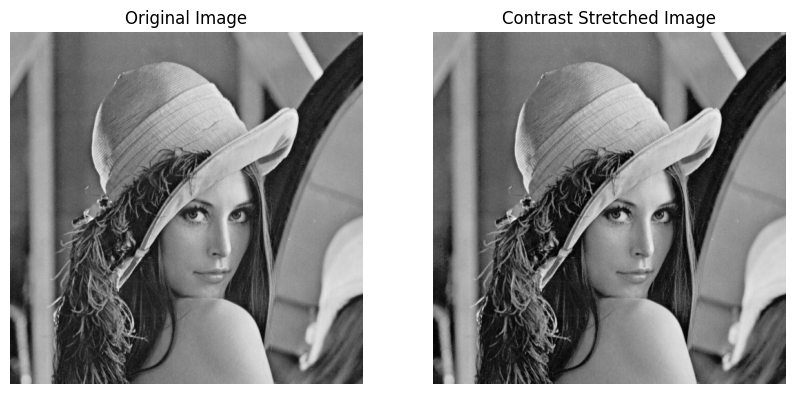

In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# Download sample image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
urllib.request.urlretrieve(url, "input.jpg")

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Input ranges
r1 = int(input("Enter input minimum intensity: "))
r2 = int(input("Enter input maximum intensity: "))
s1 = int(input("Enter output minimum intensity: "))
s2 = int(input("Enter output maximum intensity: "))

if not (0 <= r1 < r2 <= 255):
    raise ValueError("Input range must satisfy 0 <= r1 < r2 <= 255")
if not (0 <= s1 <= s2 <= 255):
    raise ValueError("Output range must be between 0 and 255")

# Linear contrast stretching
img_float = img.astype(np.float32)
result = img_float.copy()

mask = (img_float >= r1) & (img_float <= r2)
result[mask] = s1 + (
    (img_float[mask] - r1) * (s2 - s1) / (r2 - r1)
)

# Clip values and convert to uint8
result = np.clip(result, 0, 255).astype(np.uint8)

# Display images
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result, cmap="gray")
plt.title("Contrast Stretched Image")
plt.axis("off")
plt.show()
